In [1]:
from transformers import AutoTokenizer, CLIPImageProcessor
from processor import myLlavaProcessor
from model import LLaVaConfig

In [2]:
config = LLaVaConfig(
    base_model="gpt2",
    clip_model="openai/clip-vit-base-patch16"
)
 
CHAT_TEMPLATE = (
    "{% if messages[0]['role'] == 'system' %}"
    "{% set system_message = messages[0]['content'] %}"
    "{{ '<|im_start|>system\\n' + system_message + '<|im_end|>\\n' }}"
    "{% else %}"
    "{{ '<|im_start|>system\\nYou are a helpful assistant<|im_end|>\\n' }}"
    "{% endif %}"
    "{% for message in messages %}"
    "{% set content = message['content'] %}"
    "{% if message['role'] == 'user' %}"
    "{{ '<|im_start|>user\\n' + content + '<|im_end|>\\n<|im_start|>assistant\\n' }}"
    "{% elif message['role'] == 'assistant' %}"
    "{% generation %}"    # for `DataCollatorForSeq2Seq` generate labels
    "{{ content + '<|im_end|>' + '\\n' }}"
    "{% endgeneration %}" # for `DataCollatorForSeq2Seq` generate labels
    "{% endif %}"
    "{% endfor %}"
)

In [3]:
tokenizer = AutoTokenizer.from_pretrained(config.base_model, trust_remote_code=True)
image_processor = CLIPImageProcessor.from_pretrained(config.clip_model)
if config.image_token not in tokenizer.vocab:
    tokenizer.add_special_tokens({"additional_special_tokens": [config.image_token]})
config.image_token_id = tokenizer.convert_tokens_to_ids(config.image_token)
print(f"{config.image_token}: {config.image_token_id}")
processor = myLlavaProcessor(image_processor=image_processor, tokenizer=tokenizer, patch_size=16, chat_template=CHAT_TEMPLATE)

<image>: 50257


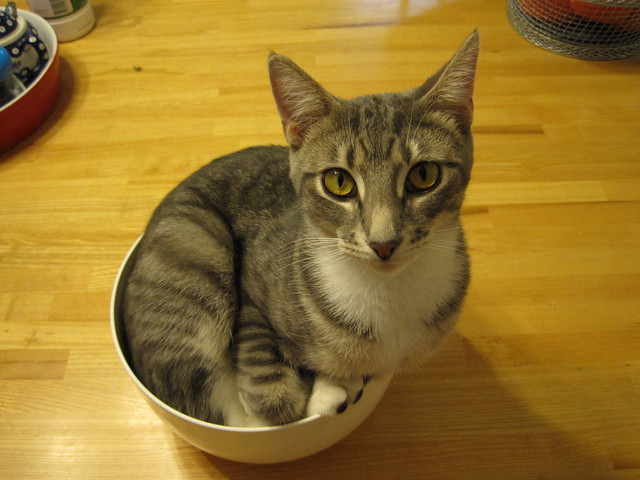

In [4]:
sample = {
    "message": [
      {
        "role": "user",
        "content": "请简单描述一下图片中的内容。<image>"
      },
      {
        "role": "assistant",
        "content": "图像描述了一只蹲在盆中的猫。"
      }
    ],
    "image": "https://farm7.staticflickr.com/6168/6178664265_39dbd8174c_z.jpg"
}

def download_image(url):
    from PIL import Image
    import requests
    from io import BytesIO

    response = requests.get(url)
    return Image.open(BytesIO(response.content))

message = sample['message']
image = download_image(sample['image'])
image

In [5]:
text = processor.apply_chat_template(message)
output = processor(images=image, text=text)
print(output)

{'input_ids': tensor([[   27,    91,   320,    62,  9688,    91,    29, 10057,   198,  1639,
           389,   257,  7613,  8796,    27,    91,   320,    62,   437,    91,
            29,   198,    27,    91,   320,    62,  9688,    91,    29,  7220,
           198, 46237,   115,   163,   106,   222, 39355,   243,   162,   237,
           237, 32573,   108, 31660, 10310,   233, 32368,   122, 31965,   229,
         40792, 21410, 37863,   227, 22522,   117, 16764, 50257, 50257, 50257,
         50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
         50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
         50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
         50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
         50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
         50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257, 50257,
         50257, 50257, 50257, 50257, 5

In [6]:
print(tokenizer.decode(output['input_ids'].squeeze(), skip_special_tokens=False))

<|im_start|>system
You are a helpful assistant<|im_end|>
<|im_start|>user
请简单描述一下图片中的内容。<image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><image><i